# UIDE · Visión por Computador · Laboratorio 02
## Detección de objetos con YOLO: confianza, IoU, NMS y latencia

**Duración en clase:** 35 minutos · **Entorno:** Google Colab (CPU o GPU T4)  
**Nivel:** Maestría, intermedio · **Versión docente:** 1.0

**Objetivos**
1. Ejecutar un detector YOLO preentrenado sobre fotografías.
2. Interpretar clases, cajas delimitadoras y puntuaciones de confianza.
3. Comparar umbrales de confianza, IoU de NMS y tamaño de imagen.
4. Calcular manualmente la intersección sobre unión (IoU).
5. Diferenciar confianza, IoU, mAP y latencia; reconocer límites de un detector genérico.

> **Caso transversal:** inspección visual en una línea de producción. El detector COCO usado aquí es **demostrativo**: no identifica automáticamente defectos ni grados de madurez del banano. Para eso se requieren clases, anotaciones y validación específicas.

**Ruta de trabajo:** 0–5 min preparación · 5–12 min primera detección · 12–20 min parámetros · 20–27 min IoU y NMS · 27–35 min rendimiento y discusión.

### 1 · Preparación del entorno
Ejecuta la siguiente celda. En Colab puedes elegir **Entorno de ejecución → Cambiar tipo de entorno → T4 GPU** si está disponible, pero el modelo pequeño también funciona en CPU.

**Nota docente:** explica la diferencia entre los pesos preentrenados y el dataset usado para evaluar un detector. Los pesos se descargan una vez por entorno nuevo.

In [14]:
%pip -q install "ultralytics>=8.3,<9" matplotlib pillow pandas requests

import time, io, requests
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
from ultralytics import YOLO

SEED = 42
np.random.seed(SEED)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
DISPOSITIVO = 0 if torch.cuda.is_available() else "cpu"
modelo = YOLO("yolo11n.pt")  # Modelo nano preentrenado en COCO
print("Modelo cargado. Clases disponibles:", len(modelo.names))


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
PyTorch: 2.14.1
CUDA: False
Modelo cargado. Clases disponibles: 80


### 2 · Imágenes de prueba
Usaremos dos imágenes de demostración públicas de Ultralytics. Si la descarga falla, la celda mostrará un error claro; vuelve a intentarlo o coloca una fotografía propia en la carpeta del laboratorio.

**Actividad:** antes de ejecutar el detector, predice qué objetos encontrará.

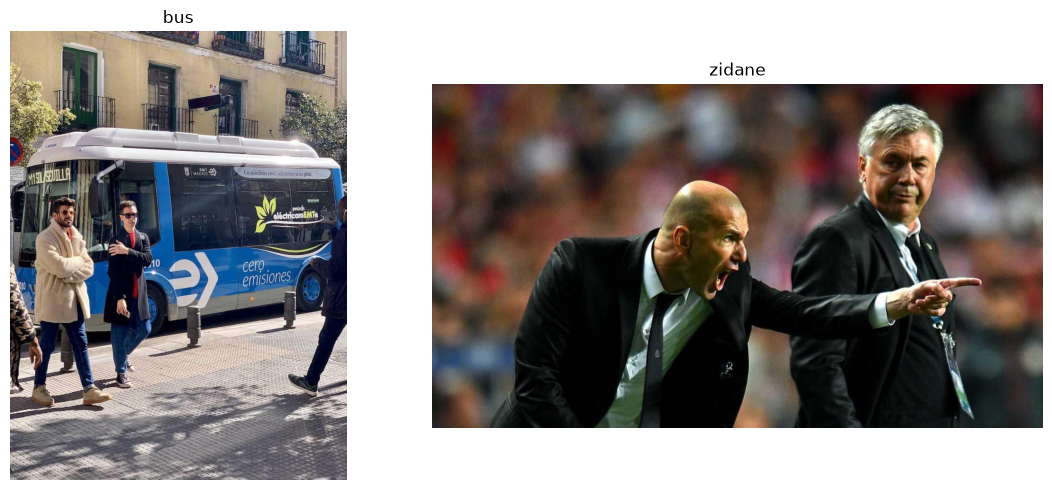

In [15]:
# /content existe en Colab; en local usamos una carpeta escribible en el directorio de trabajo
CARPETA = Path("/content/vision_lab02") if Path("/content").is_dir() else Path.cwd() / "vision_lab02"
CARPETA.mkdir(parents=True, exist_ok=True)
FUENTES = {
    "bus": "https://ultralytics.com/images/bus.jpg",
    "zidane": "https://ultralytics.com/images/zidane.jpg",
}
imagenes = {}
for nombre, url in FUENTES.items():
    destino = CARPETA / f"{nombre}.jpg"
    if not destino.exists():
        r = requests.get(url, timeout=30)
        r.raise_for_status()
        Image.open(io.BytesIO(r.content)).convert("RGB").save(destino)
    imagenes[nombre] = destino

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, ruta) in zip(axs, imagenes.items()):
    ax.imshow(Image.open(ruta))
    ax.set_title(nombre)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3 · Primera detección
Cada predicción contiene `boxes.xyxy` (coordenadas), `boxes.conf` (confianza) y `boxes.cls` (identificador de clase).

**Pregunta:** ¿una confianza del 0.90 significa que el modelo tiene 90 % de accuracy? **No**: es una puntuación para una detección individual, no una métrica global de evaluación.

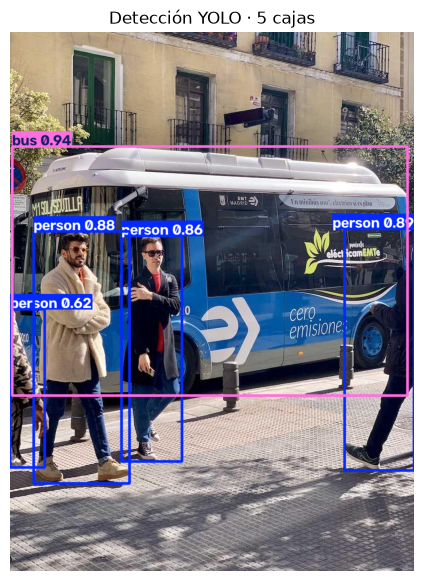

,clase,confianza,xyxy
0,bus,0.940,"[4.0, 229.5, 796.4, 728.6]"
1,person,0.888,"[670.8, 394.9, 809.8, 878.4]"
2,person,0.880,"[47.5, 399.6, 239.3, 904.1]"
3,person,0.857,"[223.1, 408.6, 344.6, 860.4]"
4,person,0.616,"[0.0, 555.8, 69.5, 872.7]"


Tiempo total de la llamada: 0.279 s (incluye sobrecargas y posible calentamiento)


In [16]:
ruta = str(imagenes["bus"])
t0 = time.perf_counter()
resultado = modelo.predict(source=ruta, conf=0.25, imgsz=640,
                           device=DISPOSITIVO, verbose=False)[0]
tiempo_total = time.perf_counter() - t0

plt.figure(figsize=(11, 7))
plt.imshow(resultado.plot()[..., ::-1])  # BGR → RGB
plt.axis("off")
plt.title(f"Detección YOLO · {len(resultado.boxes)} cajas")
plt.show()

filas = []
for caja in resultado.boxes:
    cls = int(caja.cls.item())
    filas.append({
        "clase": modelo.names[cls],
        "confianza": round(float(caja.conf.item()), 3),
        "xyxy": [round(float(v), 1) for v in caja.xyxy[0].tolist()]
    })
display(pd.DataFrame(filas))
print(f"Tiempo total de la llamada: {tiempo_total:.3f} s (incluye sobrecargas y posible calentamiento)")

### 4 · Experimento A: umbral de confianza
Modifica `UMBRALES` y observa qué detecciones desaparecen. **No interpretes menos cajas como automáticamente mejor desempeño.** Podrías estar eliminando verdaderos positivos.

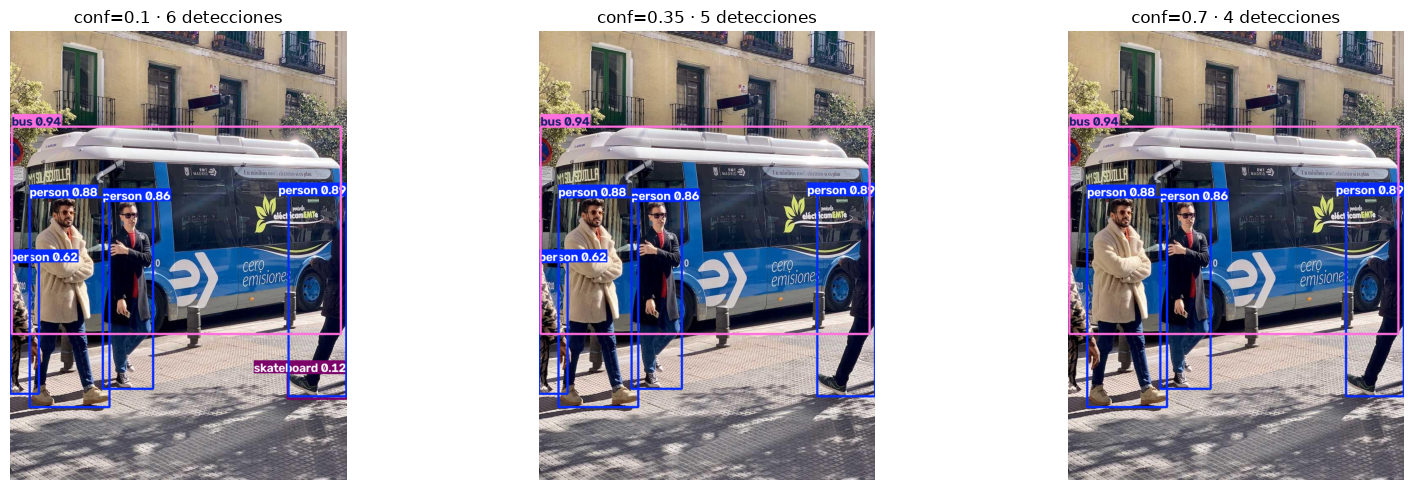

,conf,detecciones
0,0.10,6
1,0.35,5
2,0.70,4


In [17]:
UMBRALES = [0.10, 0.35, 0.70]
fig, axs = plt.subplots(1, len(UMBRALES), figsize=(17, 5))
resumen_conf = []
for ax, umbral in zip(axs, UMBRALES):
    res = modelo.predict(source=ruta, conf=umbral, imgsz=640,
                         device=DISPOSITIVO, verbose=False)[0]
    ax.imshow(res.plot()[..., ::-1])
    ax.set_title(f"conf={umbral} · {len(res.boxes)} detecciones")
    ax.axis("off")
    resumen_conf.append({"conf": umbral, "detecciones": len(res.boxes)})
plt.tight_layout()
plt.show()
display(pd.DataFrame(resumen_conf))

### 5 · IoU: cálculo reproducible
IoU mide cuánto se superponen dos cajas: **área de intersección / área de unión**. Compara una predicción con su anotación real (*ground truth*) o dos cajas entre sí.

Las cajas siguientes son **didácticas**, no anotaciones de las fotografías. Su IoU **no mide** la calidad de YOLO en esas imágenes.

IoU entre A y B: 0.402


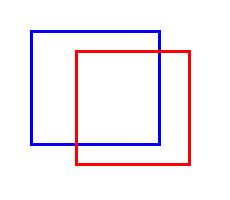

In [18]:
def calcular_iou(a, b):
    # a, b = [x1, y1, x2, y2]
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

A = [30, 30, 160, 145]
B = [75, 50, 190, 165]
iou = calcular_iou(A, B)
print(f"IoU entre A y B: {iou:.3f}")
canvas = Image.new("RGB", (230, 200), "white")
d = ImageDraw.Draw(canvas)
d.rectangle(A, outline="blue", width=3)
d.rectangle(B, outline="red", width=3)
display(canvas)
assert 0 <= iou <= 1

# RETO: mueve la caja B y explica qué ocurre con el IoU.

### 6 · Experimento B: IoU de NMS
El parámetro `iou` en `predict()` es el umbral usado en **Non-Maximum Suppression (NMS)** para decidir qué cajas solapadas se descartan. **No es** el IoU de evaluación de una predicción respecto a la verdad de terreno.

Prueba valores distintos. Es posible que no cambie nada en estas imágenes; eso también es un resultado válido.

In [19]:
UMBRALES_NMS = [0.30, 0.70]
filas_nms = []
for umbral in UMBRALES_NMS:
    res = modelo.predict(source=ruta, conf=0.20, iou=umbral,
                         imgsz=640, device=DISPOSITIVO, verbose=False)[0]
    filas_nms.append({"iou_NMS": umbral, "detecciones": len(res.boxes)})
display(pd.DataFrame(filas_nms))
print("Discusión: ¿por qué el umbral NMS no es equivalente a mAP@0.5?")

,iou_NMS,detecciones
0,0.3,5
1,0.7,5


Discusión: ¿por qué el umbral NMS no es equivalente a mAP@0.5?


### 7 · Experimento C: tamaño de entrada y tiempo
Compararemos dos tamaños de imagen. Hacemos una ejecución de calentamiento y medimos varias repeticiones para reducir el efecto del arranque. **No es un benchmark industrial**: Colab, la carga compartida y el hardware influyen en los tiempos.

In [20]:
TAMANOS = [320, 640]
REPETICIONES = 3
mediciones = []
for tam in TAMANOS:
    modelo.predict(source=ruta, conf=0.25, imgsz=tam,
                   device=DISPOSITIVO, verbose=False)  # warm-up
    tiempos = []
    cantidad = None
    for _ in range(REPETICIONES):
        t0 = time.perf_counter()
        res = modelo.predict(source=ruta, conf=0.25, imgsz=tam,
                             device=DISPOSITIVO, verbose=False)[0]
        tiempos.append((time.perf_counter()-t0)*1000)
        cantidad = len(res.boxes)
    mediciones.append({
        "imgsz": tam,
        "detecciones": cantidad,
        "latencia_mediana_ms": round(float(np.median(tiempos)), 1)
    })
display(pd.DataFrame(mediciones))
print("¿Qué configuración recomendarías para una cámara de inspección? ¿Qué falta medir?")

,imgsz,detecciones,latencia_mediana_ms
0,320,5,17.5
1,640,5,47.4


¿Qué configuración recomendarías para una cámara de inspección? ¿Qué falta medir?


### 8 · Métricas: lo que **no** podemos concluir con estas imágenes
- **Confianza:** puntuación de una detección.
- **IoU:** superposición entre dos cajas.
- **Precision y recall:** requieren conocer verdaderos positivos, falsos positivos y falsos negativos.
- **mAP:** agrega la precisión media por clase y umbrales de evaluación, usando imágenes **anotadas**.

**No calcularemos mAP a partir de dos imágenes sin anotaciones.** Como extensión opcional, se puede evaluar el detector con un conjunto anotado de referencia (`coco8.yaml`) usando `modelo.val(...)`. Esa extensión requiere descargar datos y puede tomar más tiempo; no es necesaria para completar el laboratorio.

In [21]:
# EXTENSIÓN OPCIONAL: ejecutar solo si queda tiempo y hay conexión.
EJECUTAR_MAP = False
if EJECUTAR_MAP:
    metricas = modelo.val(data="coco8.yaml", imgsz=640,
                          device=DISPOSITIVO, verbose=False)
    print("mAP50:", round(metricas.box.map50, 3))
    print("mAP50-95:", round(metricas.box.map, 3))
else:
    print("Evaluación mAP omitida en la práctica base (requiere dataset anotado).")

Evaluación mAP omitida en la práctica base (requiere dataset anotado).


### 9 · Mini desafío: inspección industrial (4 minutos)
Una empacadora quiere identificar y contar bananos en una cinta, y después separar los que tienen defectos superficiales.

Responde en parejas:
1. ¿Qué puede resolver un detector de objetos genérico y qué **no** puede resolver?
2. ¿Qué clases y anotaciones necesitarías para un detector especializado?
3. ¿Qué priorizarías: recall o precision si dejar pasar una fruta defectuosa es más costoso que retirarla para revisión?
4. ¿Cómo comprobarías el rendimiento ante cambios de iluminación y objetos solapados?

**Conclusión esperada:** seleccionar una arquitectura requiere evaluar datos reales, tipos de error, latencia y condiciones de operación; no basta con una imagen de demostración.

**Para el docente:** pide una justificación oral de 30 segundos a dos equipos. Conecta con el próximo laboratorio de segmentación: cuando necesitamos contornos o superficies defectuosas, las cajas pueden resultar insuficientes.

---
### Referencias y notas de reproducibilidad
- [Ultralytics — documentación de predicción](https://docs.ultralytics.com/modes/predict/)
- [Ultralytics — documentación de validación](https://docs.ultralytics.com/modes/val/)
- [Ultralytics — modelos YOLO11](https://docs.ultralytics.com/models/yolo11/)
- [COCO — dataset y categorías](https://cocodataset.org/)

**Nota:** este laboratorio usa `yolo11n.pt` por estabilidad y bajo costo de cómputo; no pretende representar el modelo YOLO más reciente. Las imágenes son de demostración. Las cifras exactas dependen del entorno y de la versión instalada.

**Checklist docente:** ejecutar desde un entorno nuevo, verificar descargas, registrar latencia CPU/T4 y confirmar que las visualizaciones se muestran correctamente antes de la clase.